<a href="https://colab.research.google.com/github/Sanugiw/ml-fastvit/blob/Imesh/fastvit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/Sanugiw/ml-fastvit.git
%cd ml-fastvit

Cloning into 'ml-fastvit'...
remote: Enumerating objects: 78, done.
remote: Counting objects: 100% (49/49), done.
remote: Compressing objects: 100% (36/36), done.
remote: Total 78 (delta 24), reused 27 (delta 12), pack-reused 29 (from 1)
Receiving objects: 100% (78/78), 3.16 MiB | 7.36 MiB/s, done.
Resolving deltas: 100% (26/26), done.
/content/ml-fastvit


In [ ]:
!pip install -r requirements.txt

In [ ]:
%cd /content/ml-fastvit

import os
import torch

print("Files:", os.listdir("."))
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

/content/ml-fastvit
Files: ['requirements.txt', 'models', '.gitignore', 'README.md', 'docs', 'export_model.py', 'misc', '.git', 'validate.py', 'LICENSE', 'ACKNOWLEDGEMENTS', 'train.py']
PyTorch: 2.14.1+cpu
CUDA available: False


In [ ]:
!cat requirements.txt

timm
scipy


In [ ]:
!ls -la

total 164
drwxr-xr-x 6 root root  4096 Nov 23 08:42 .
drwxr-xr-x 1 root root  4096 Nov 23 08:42 ..
-rw-r--r-- 1 root root 37036 Nov 23 08:42 ACKNOWLEDGEMENTS
drwxr-xr-x 4 root root  4096 Nov 23 08:42 docs
-rw-r--r-- 1 root root  2479 Nov 23 08:42 export_model.py
drwxr-xr-x 8 root root  4096 Nov 23 08:42 .git
-rw-r--r-- 1 root root  1822 Nov 23 08:42 .gitignore
-rw-r--r-- 1 root root  2666 Nov 23 08:42 LICENSE
drwxr-xr-x 2 root root  4096 Nov 23 08:42 misc
drwxr-xr-x 3 root root  4096 Nov 23 08:42 models
-rw-r--r-- 1 root root 15446 Nov 23 08:42 README.md
-rw-r--r-- 1 root root    11 Nov 23 08:42 requirements.txt
-rw-r--r-- 1 root root 46744 Nov 23 08:42 train.py
-rw-r--r-- 1 root root 16610 Nov 23 08:42 validate.py


In [ ]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# List the contents of the main My Drive directory to locate the dataset folder
drive_path = '/content/drive/MyDrive'
if os.path.exists(drive_path):
    print("Drive Contents:", os.listdir(drive_path))
else:
    print("Google Drive is not accessible.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive Contents: ['Colab Notebooks', 'Getting started.pdf', 'Classroom', 'Imesh Mareesha - online Q 3 gc.docx', 'Imesh Mareesha - online Q 2 GC.docx', 'EA20BAAE-22BD-47CC-A1F4-4072C098450A.jpeg', 'e08f90', 'IMG_2113 (1).HEIC', 'IMG_2114 (1).HEIC', 'IMG_2121 (1).HEIC', 'IMG_2133 (1).HEIC', 'IMG_2134 (1).HEIC', 'IMG_2113.HEIC', 'IMG_2121.HEIC', 'IMG_2114.HEIC', 'IMG_2122.HEIC', 'IMG_2133.HEIC', 'IMG_2134.HEIC', 'IMG_2113.pdf', 'HNB_Transfer_Receipt_30_09_2022_03_14_PM (1).pdf', 'HNB_Transfer_Receipt_30_09_2022_03_14_PM.pdf', 'HNB_Transfer_Receipt_09_11_2022_07_10_AM.pdf', 'HNB_Transfer_Receipt_26_01_2023_10_53_PM.pdf', 'CA85DF7A-ADFB-4318-8629-232E02A54F10.jpeg', 'HNB_Transfer_Receipt_15_03_2023_02_28_PM.pdf', '0097240B-4DEB-4851-BC2D-8649CD23BE25.jpeg', 'HNB_Transfer_Receipt_05_04_2023_02_56_PM.pdf', 'HNB_Transfer_Receipt_08_04_2023_11_03_PM.pdf', '2nd order DE

In [ ]:
import os
import shutil
import zipfile
from sklearn.model_selection import train_test_split

# Define target structured directory
dataset_root = "/content/imagenet-1k"
os.makedirs(dataset_root, exist_ok=True)

# Define helper to organize a flat or class-based folder into ImageNet-1k format
def structure_dataset(source_dir, train_ratio=0.8):
    """
    Collects all images from source_dir, splits them into train/val,
    and structures them as required.
    """
    print(f"Scanning source directory: {source_dir}")
    categories = [d for d in os.listdir(source_dir) if os.path.isdir(os.path.join(source_dir, d))]

    if not categories:
        print("No subdirectories found. Assuming single class or flat image folder.")
        categories = ['.']

    for category in categories:
        cat_path = os.path.join(source_dir, category) if category != '.' else source_dir
        # Filter image formats
        images = [f for f in os.listdir(cat_path) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp', '.bmp'))]
        if not images:
            continue

        # Resolve category name safely
        cat_name = "class_0" if category == '.' else category

        train_imgs, val_imgs = train_test_split(images, test_size=(1.0 - train_ratio), random_state=42)

        # Create directories
        os.makedirs(os.path.join(dataset_root, 'train', cat_name), exist_ok=True)
        os.makedirs(os.path.join(dataset_root, 'validation', cat_name), exist_ok=True)

        # Copy files
        for img in train_imgs:
            shutil.copy(os.path.join(cat_path, img), os.path.join(dataset_root, 'train', cat_name, img))
        for img in val_imgs:
            shutil.copy(os.path.join(cat_path, img), os.path.join(dataset_root, 'validation', cat_name, img))

    print(f"Structuring complete! Your dataset is now prepared at: {dataset_root}")

# Example usage: Set 'source_path' to point to your specific dataset folder/zip inside Google Drive
# e.g., source_path = '/content/drive/MyDrive/octwave_artifacts' or we can extract a ZIP file.
source_path = '/content/drive/MyDrive/octwave_artifacts' # Update this path to match your target dataset

if os.path.exists(source_path):
    if source_path.endswith('.zip'):
        print("Unzipping dataset to temp folder...")
        with zipfile.ZipFile(source_path, 'r') as zip_ref:
            zip_ref.extractall('/content/temp_dataset')
        structure_dataset('/content/temp_dataset')
    else:
        structure_dataset(source_path)
else:
    print(f"Specified source path '{source_path}' does not exist. Please update 'source_path' to point to your dataset directory or zip file in Drive.")

Scanning source directory: /content/drive/MyDrive/octwave_artifacts
Structuring complete! Your dataset is now prepared at: /content/imagenet-1k


In [ ]:
import os

drive_path = '/content/drive/MyDrive'

# Search Google Drive for files or folders matching 'imagenet'
matches = []
for root, dirs, files in os.walk(drive_path):
    # Limit search depth to keep it fast
    depth = root.replace(drive_path, '').count(os.sep)
    if depth > 2:
        continue
    for name in dirs + files:
        if 'imagenet' in name.lower():
            matches.append(os.path.join(root, name))

print("Found matching ImageNet files/folders on your Drive:")
for m in matches:
    print(m)

Found matching ImageNet files/folders on your Drive:
/content/drive/MyDrive/ImageNet1K
/content/drive/MyDrive/ImageNet1K/imagenet1k-train-0000.tar
/content/drive/MyDrive/ImageNet1K/imagenet1k-train-0001.tar
/content/drive/MyDrive/ImageNet1K/imagenet1k-train-0002.tar
/content/drive/MyDrive/ImageNet1K/imagenet1k-train-0003.tar
/content/drive/MyDrive/ImageNet1K/imagenet1k-train-0004.tar
/content/drive/MyDrive/ImageNet1K/imagenet1k-train-0005.tar
/content/drive/MyDrive/ImageNet1K/imagenet1k-train-0006.tar
/content/drive/MyDrive/ImageNet1K/imagenet1k-train-0007.tar
/content/drive/MyDrive/ImageNet1K/imagenet1k-train-0008.tar
/content/drive/MyDrive/ImageNet1K/imagenet1k-train-0009.tar
/content/drive/MyDrive/ImageNet1K/imagenet1k-train-0010.tar
/content/drive/MyDrive/ImageNet1K/imagenet1k-train-0011.tar
/content/drive/MyDrive/ImageNet1K/imagenet1k-train-0012.tar
/content/drive/MyDrive/ImageNet1K/imagenet1k-train-0013.tar
/content/drive/MyDrive/ImageNet1K/imagenet1k-train-0014.tar
/content/driv

In [ ]:
import os
import tarfile
import shutil

# Target directory structure
base_dir = "/content/imagenet-1k"
train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "validation")

os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)

source_folder = "/content/drive/MyDrive/ImageNet1K"
all_files = sorted(os.listdir(source_folder))
tar_files = [f for f in all_files if f.endswith('.tar')]

print(f"Found {len(tar_files)} tar archives in Google Drive.")

# Let's write a helper to safely extract tar files into structured directories
def extract_tar_to_imagenet(tar_path, target_root):
    print(f"Extracting {os.path.basename(tar_path)}...")
    with tarfile.open(tar_path, "r") as tar:
        # Check files inside the archive to match structure
        for member in tar.getmembers():
            if member.isfile():
                # Standard ImageNet archives contain paths like: train/n01440764/n01440764_10026.JPEG
                # Or flat files. We'll extract them preserving/creating class directories.
                name_parts = member.name.strip("/").split("/")

                if len(name_parts) >= 3 and name_parts[0] in ['train', 'val', 'validation']:
                    # Format matches: split/class/image.JPEG
                    split, category, img_name = name_parts[0], name_parts[1], name_parts[-1]
                    target_split = 'validation' if split in ['val', 'validation'] else 'train'
                    dest_folder = os.path.join(base_dir, target_split, category)
                else:
                    # If it's just class/image.JPEG or flat files, default to train folder under a structured category
                    category = name_parts[-2] if len(name_parts) > 1 else "unknown_class"
                    dest_folder = os.path.join(train_dir, category)

                os.makedirs(dest_folder, exist_ok=True)
                member.name = os.path.basename(member.name)
                tar.extract(member, path=dest_folder)

# For demonstration and system limits, let's extract the first few shards to build the structure.
# You can change the slice [:5] to extract all archives.
shards_to_extract = tar_files[:3]
for tar_file in shards_to_extract:
    full_path = os.path.join(source_folder, tar_file)
    try:
        extract_tar_to_imagenet(full_path, base_dir)
    except Exception as e:
        print(f"Error extracting {tar_file}: {e}")

# Show final structured directories
print("\nStructuring Check:")
for split in ['train', 'validation']:
    split_path = os.path.join(base_dir, split)
    if os.path.exists(split_path):
        classes = sorted(os.listdir(split_path))[:5]
        print(f"{split}/ contains {len(os.listdir(split_path))} classes. Examples: {classes}")

Found 130 tar archives in Google Drive.
Extracting imagenet1k-train-0000.tar...


/tmp/ipykernel_354/3956707016.py:42: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(member, path=dest_folder)


Extracting imagenet1k-train-0001.tar...
Error extracting imagenet1k-train-0001.tar: [Errno 107] Transport endpoint is not connected
Extracting imagenet1k-train-0002.tar...
Error extracting imagenet1k-train-0002.tar: [Errno 107] Transport endpoint is not connected: '/content/drive/MyDrive/ImageNet1K/imagenet1k-train-0002.tar'

Structuring Check:
train/ contains 1 classes. Examples: ['unknown_class']
validation/ contains 0 classes. Examples: []


In [ ]:
import os
import shutil
import tarfile

# Create local directories
local_tar_dir = "/content/temp_tars"
os.makedirs(local_tar_dir, exist_ok=True)

base_dir = "/content/imagenet-1k"
train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "validation")
os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)

source_folder = "/content/drive/MyDrive/ImageNet1K"

# Copying just 2 shards locally to test and structure them fast without timing out
shards_to_copy = ['imagenet1k-train-0000.tar', 'imagenet1k-train-0001.tar']

for shard in shards_to_copy:
    src_path = os.path.join(source_folder, shard)
    dst_path = os.path.join(local_tar_dir, shard)
    if os.path.exists(src_path) and not os.path.exists(dst_path):
        print(f"Copying {shard} locally...")
        shutil.copy(src_path, dst_path)

print("Local copies completed. Checking archive internal structure...")

# Inspect the structure of the first archive
test_tar = os.path.join(local_tar_dir, 'imagenet1k-train-0000.tar')
if os.path.exists(test_tar):
    with tarfile.open(test_tar, 'r') as tar:
        members = tar.getmembers()
        print(f"Total items in {shards_to_copy[0]}: {len(members)}")
        print("Sample files inside archive:")
        for m in members[:10]:
            print(m.name)

Copying imagenet1k-train-0000.tar locally...
Copying imagenet1k-train-0001.tar locally...
Local copies completed. Checking archive internal structure...
Total items in imagenet1k-train-0000.tar: 3753
Sample files inside archive:
n02097047_2079.cls
n02097047_2079.jpg
n02097047_2079.json
n01682714_8546.cls
n01682714_8546.jpg
n01682714_8546.json
n03134739_3100.cls
n03134739_3100.jpg
n03134739_3100.json
n04254777_3064.cls


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os
import tarfile
import shutil
from sklearn.model_selection import train_test_split

# Configure paths
local_tar_dir = "/content/temp_tars"
base_dir = "/content/imagenet-1k"
train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "validation")

os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)

tar_files = [f for f in os.listdir(local_tar_dir) if f.endswith('.tar')]
print(f"Processing local tar files: {tar_files}")

# Group images by their class extracted from filenames
class_image_mapping = {}

for tar_name in tar_files:
    tar_path = os.path.join(local_tar_dir, tar_name)
    print(f"Scanning structure of {tar_name}...")
    with tarfile.open(tar_path, 'r') as tar:
        for member in tar.getmembers():
            if member.isfile() and member.name.lower().endswith(('.jpg', '.jpeg', '.png')):
                filename = os.path.basename(member.name)
                # Parse WordNet class ID (e.g., 'n02097047_2079.jpg' -> 'n02097047')
                class_id = filename.split('_')[0]
                if class_id not in class_image_mapping:
                    class_image_mapping[class_id] = []
                class_image_mapping[class_id].append((tar_path, member))

print(f"Found {len(class_image_mapping)} unique classes across shards.")

# Split and extract images into standard train/validation class subdirectories
for class_id, items in class_image_mapping.items():
    # Ensure we have class subfolders
    os.makedirs(os.path.join(train_dir, class_id), exist_ok=True)
    os.makedirs(os.path.join(val_dir, class_id), exist_ok=True)

    # If class has multiple images, split train/validation (80/20)
    if len(items) > 1:
        train_items, val_items = train_test_split(items, test_size=0.2, random_state=42)
    else:
        train_items, val_items = items, []

    # Extract to target destinations
    for tar_path, member in train_items:
        with tarfile.open(tar_path, 'r') as tar:
            member.name = os.path.basename(member.name)
            tar.extract(member, path=os.path.join(train_dir, class_id))

    for tar_path, member in val_items:
        with tarfile.open(tar_path, 'r') as tar:
            member.name = os.path.basename(member.name)
            tar.extract(member, path=os.path.join(val_dir, class_id))

# Validation check
print("\nDataset Structuring Completed Successfully!")
for split in ['train', 'validation']:
    split_path = os.path.join(base_dir, split)
    classes = sorted(os.listdir(split_path))
    print(f"{split_path}/ has {len(classes)} classes.")
    if classes:
        sample_class = classes[0]
        sample_class_path = os.path.join(split_path, sample_class)
        print(f"  -> Sample class '{sample_class}' contains: {os.listdir(sample_class_path)[:3]}")

Processing local tar files: ['imagenet1k-train-0001.tar', 'imagenet1k-train-0000.tar']
Scanning structure of imagenet1k-train-0001.tar...
Scanning structure of imagenet1k-train-0000.tar...
Found 918 unique classes across shards.


/tmp/ipykernel_354/3140932311.py:52: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(member, path=os.path.join(train_dir, class_id))
/tmp/ipykernel_354/3140932311.py:57: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(member, path=os.path.join(val_dir, class_id))



Dataset Structuring Completed Successfully!
/content/imagenet-1k/train/ has 919 classes.
  -> Sample class 'n01440764' contains: ['n01440764_13116.jpg']
/content/imagenet-1k/validation/ has 918 classes.
  -> Sample class 'n01440764' contains: ['n01440764_8528.jpg']


In [ ]:
import os

train_path = '/content/imagenet-1k/train'
val_path = '/content/imagenet-1k/validation'

def count_images(directory):
    if not os.path.exists(directory):
        return 0
    total_count = 0
    for root, dirs, files in os.walk(directory):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg', '.webp', '.bmp')):
                total_count += 1
    return total_count

num_train_images = count_images(train_path)
num_val_images = count_images(val_path)

print(f"Total training images: {num_train_images}")
print(f"Total validation/test images: {num_val_images}")
print(f"Combined total images: {num_train_images + num_val_images}")

Total training images: 3001
Total validation/test images: 752
Combined total images: 3753


In [ ]:
import os

train_path = '/content/imagenet-1k/train'
val_path = '/content/imagenet-1k/validation'

def get_directory_size_gb(directory):
    if not os.path.exists(directory):
        return 0.0
    total_size_bytes = 0
    for root, dirs, files in os.walk(directory):
        for file in files:
            file_path = os.path.join(root, file)
            try:
                total_size_bytes += os.path.getsize(file_path)
            except OSError:
                pass
    return total_size_bytes / (1024 ** 3)

train_size_gb = get_directory_size_gb(train_path)
val_size_gb = get_directory_size_gb(val_path)
total_size_gb = train_size_gb + val_size_gb

print(f"Training images size: {train_size_gb:.4f} GB")
print(f"Validation images size: {val_size_gb:.4f} GB")
print(f"Total dataset size: {total_size_gb:.4f} GB")

Training images size: 0.3323 GB
Validation images size: 0.0794 GB
Total dataset size: 0.4117 GB


In [ ]:
import os
import shutil
import tarfile
from sklearn.model_selection import train_test_split

# Configure paths
source_folder = "/content/drive/MyDrive/ImageNet1K"
local_tar_dir = "/content/temp_tars"
base_dir = "/content/imagenet-1k"
train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "validation")

os.makedirs(local_tar_dir, exist_ok=True)
os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)

# Find all shards in drive
all_drive_files = sorted(os.listdir(source_folder))
tar_files = [f for f in all_drive_files if f.endswith('.tar')]
print(f"Found {len(tar_files)} tar shards in Drive.")

# Loop over all shards to copy and extract dynamically to manage space and prevent disconnections
for index, shard in enumerate(tar_files):
    src_path = os.path.join(source_folder, shard)
    dst_path = os.path.join(local_tar_dir, shard)

    # 1. Copy shard locally (if not already done)
    if not os.path.exists(dst_path):
        print(f"[{index+1}/{len(tar_files)}] Copying {shard} locally...")
        try:
            shutil.copy(src_path, dst_path)
        except Exception as e:
            print(f"Error copying {shard}: {e}")
            continue

    # 2. Scan and extract directly to standard layout
    print(f"Extracting {shard}...")
    class_image_mapping = {}
    try:
        with tarfile.open(dst_path, 'r') as tar:
            for member in tar.getmembers():
                if member.isfile() and member.name.lower().endswith(('.jpg', '.jpeg', '.png')):
                    filename = os.path.basename(member.name)
                    class_id = filename.split('_')[0]
                    if class_id not in class_image_mapping:
                        class_image_mapping[class_id] = []
                    class_image_mapping[class_id].append(member)

        # Split and save classes from this shard
        for class_id, members in class_image_mapping.items():
            os.makedirs(os.path.join(train_dir, class_id), exist_ok=True)
            os.makedirs(os.path.join(val_dir, class_id), exist_ok=True)

            if len(members) > 1:
                train_items, val_items = train_test_split(members, test_size=0.2, random_state=42)
            else:
                train_items, val_items = members, []

            with tarfile.open(dst_path, 'r') as tar:
                for member in train_items:
                    member.name = os.path.basename(member.name)
                    tar.extract(member, path=os.path.join(train_dir, class_id))
                for member in val_items:
                    member.name = os.path.basename(member.name)
                    tar.extract(member, path=os.path.join(val_dir, class_id))
    except Exception as e:
        print(f"Error processing {shard}: {e}")

    # 3. Clean up the local tar to free space
    if os.path.exists(dst_path):
        os.remove(dst_path)

print("\nAll available shards processed and structured successfully!")

Found 130 tar shards in Drive.
Extracting imagenet1k-train-0000.tar...


/tmp/ipykernel_354/2166817487.py:62: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(member, path=os.path.join(train_dir, class_id))
/tmp/ipykernel_354/2166817487.py:65: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(member, path=os.path.join(val_dir, class_id))


Extracting imagenet1k-train-0001.tar...
[3/130] Copying imagenet1k-train-0002.tar locally...
Extracting imagenet1k-train-0002.tar...
[4/130] Copying imagenet1k-train-0003.tar locally...
Extracting imagenet1k-train-0003.tar...
[5/130] Copying imagenet1k-train-0004.tar locally...
Extracting imagenet1k-train-0004.tar...
[6/130] Copying imagenet1k-train-0005.tar locally...
Extracting imagenet1k-train-0005.tar...
[7/130] Copying imagenet1k-train-0006.tar locally...
Extracting imagenet1k-train-0006.tar...
[8/130] Copying imagenet1k-train-0007.tar locally...
Extracting imagenet1k-train-0007.tar...
[9/130] Copying imagenet1k-train-0008.tar locally...
Extracting imagenet1k-train-0008.tar...
[10/130] Copying imagenet1k-train-0009.tar locally...
Extracting imagenet1k-train-0009.tar...
[11/130] Copying imagenet1k-train-0010.tar locally...
Extracting imagenet1k-train-0010.tar...
[12/130] Copying imagenet1k-train-0011.tar locally...
Extracting imagenet1k-train-0011.tar...
[13/130] Copying imagenet1k

In [ ]:
import os

base_dir = '/content/imagenet-1k'

print("Checking base directory:", os.listdir(base_dir) if os.path.exists(base_dir) else "Not Found")

for split in ['train', 'validation']:
    split_path = os.path.join(base_dir, split)
    if os.path.exists(split_path):
        subdirs = os.listdir(split_path)
        print(f"\n{split} folder contains {len(subdirs)} subdirectories (classes).")
        if subdirs:
            # Print a few samples
            print(f"Sample classes in {split}: {sorted(subdirs)[:10]}")

            # Count files in a sample class
            sample_class_path = os.path.join(split_path, subdirs[0])
            print(f"Files in class '{subdirs[0]}': {os.listdir(sample_class_path)[:5]}")

Checking base directory: Not Found


In [ ]:
import os

# Let's search recursively inside /content to find where 'imagenet-1k' or 'train' directories ended up
found_paths = []
for root, dirs, files in os.walk('/content'):
    # Stop deep traversal of git or config metadata to keep it quick
    if '.git' in root or '.config' in root:
         continue
    if 'imagenet-1k' in dirs or 'train' in dirs:
         found_paths.append(root)

print("Search Results inside /content:")
if found_paths:
    for path in set(found_paths):
        print(f"- Found relevant folders inside: {path}")
        try:
            print(f"  Contents: {os.listdir(path)[:10]}")
        except Exception:
            pass
else:
    print("Could not find any 'imagenet-1k' or 'train' directories in /content. Let's list everything in /content:")
    print(os.listdir('/content'))

Search Results inside /content:
Could not find any 'imagenet-1k' or 'train' directories in /content. Let's list everything in /content:
['.config', 'sample_data']


### Permanent Backup: Archive and Save Structured Dataset to Google Drive
This cell will run the extraction process and compress the structured `/content/imagenet-1k` directory into a single zip file saved at `/content/drive/MyDrive/imagenet1k_structured.zip`.

In [ ]:
import os
import shutil

# Source folder in Drive
drive_source = "/content/drive/MyDrive/ImageNet1K"
# Backup destination zip file
drive_backup_zip = "/content/drive/MyDrive/imagenet1k_structured.zip"

# We will compress the existing local folder once it's extracted
if os.path.exists("/content/imagenet-1k"):
    print("Archiving structured dataset to Google Drive for permanent storage...")
    shutil.make_archive("/content/drive/MyDrive/imagenet1k_structured", 'zip', "/content/imagenet-1k")
    print(f"Saved permanently to Google Drive at: {drive_backup_zip}")
else:
    print("Local structured folder /content/imagenet-1k not found. Please run the extraction shard script first, then run this to back it up permanently.")

Local structured folder /content/imagenet-1k not found. Please run the extraction shard script first, then run this to back it up permanently.


In [ ]:
import os
import shutil
import tarfile
import zipfile
from sklearn.model_selection import train_test_split

# Configure paths
source_folder = "/content/drive/MyDrive/ImageNet1K"
local_temp_extract = "/content/temp_extract"
drive_backup_zip = "/content/drive/MyDrive/imagenet1k_structured.zip"

os.makedirs(local_temp_extract, exist_ok=True)

# Find all shards in Google Drive
all_drive_files = sorted(os.listdir(source_folder))
tar_files = [f for f in all_drive_files if f.endswith('.tar')]
print(f"Found {len(tar_files)} tar shards in Drive.")

# Process and write directly to the persistent ZIP in Drive
for index, shard in enumerate(tar_files):
    src_path = os.path.join(source_folder, shard)
    local_shard_path = os.path.join("/content", shard)

    print(f"\n[{index+1}/{len(tar_files)}] Copying {shard} to local runtime...")
    try:
        shutil.copy(src_path, local_shard_path)
    except Exception as e:
        print(f"Error copying {shard}: {e}")
        continue

    print(f"Extracting and organizing {shard}...")
    class_image_mapping = {}
    try:
        with tarfile.open(local_shard_path, 'r') as tar:
            for member in tar.getmembers():
                if member.isfile() and member.name.lower().endswith(('.jpg', '.jpeg', '.png')):
                    filename = os.path.basename(member.name)
                    class_id = filename.split('_')[0]
                    if class_id not in class_image_mapping:
                        class_image_mapping[class_id] = []
                    class_image_mapping[class_id].append(member)

        # Extract files locally to temporary path
        for class_id, members in class_image_mapping.items():
            if len(members) > 1:
                train_items, val_items = train_test_split(members, test_size=0.2, random_state=42)
            else:
                train_items, val_items = members, []

            with tarfile.open(local_shard_path, 'r') as tar:
                # Save train images
                for member in train_items:
                    member.name = os.path.basename(member.name)
                    dest_dir = os.path.join(local_temp_extract, "train", class_id)
                    os.makedirs(dest_dir, exist_ok=True)
                    tar.extract(member, path=dest_dir)

                # Save validation images
                for member in val_items:
                    member.name = os.path.basename(member.name)
                    dest_dir = os.path.join(local_temp_extract, "validation", class_id)
                    os.makedirs(dest_dir, exist_ok=True)
                    tar.extract(member, path=dest_dir)

        # Append the extracted local files to the persistent Google Drive ZIP archive
        print(f"Appending {shard} to permanent Google Drive ZIP archive...")
        with zipfile.ZipFile(drive_backup_zip, 'a', zipfile.ZIP_DEFLATED) as zipf:
            for root, _, files in os.walk(local_temp_extract):
                for file in files:
                    file_path = os.path.join(root, file)
                    arcname = os.path.relpath(file_path, local_temp_extract)
                    zipf.write(file_path, arcname)

        # Clean up temporary folders and copied shard to free local space
        shutil.rmtree(local_temp_extract)
        os.makedirs(local_temp_extract, exist_ok=True)
        if os.path.exists(local_shard_path):
            os.remove(local_shard_path)

        print(f"Successfully backed up and cleaned {shard}!")

    except Exception as e:
        print(f"Error processing {shard}: {e}")

print("\nAll shards have been processed and permanently stored in your Google Drive ZIP file!")

Found 130 tar shards in Drive.

[1/130] Copying imagenet1k-train-0000.tar to local runtime...
Extracting and organizing imagenet1k-train-0000.tar...


/tmp/ipykernel_353/1054508305.py:56: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(member, path=dest_dir)
/tmp/ipykernel_353/1054508305.py:63: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(member, path=dest_dir)


Appending imagenet1k-train-0000.tar to permanent Google Drive ZIP archive...


KeyboardInterrupt: 

### Option 1: Persistent Extraction Directly to Google Drive
This cell reads your `.tar` shards from `/content/drive/MyDrive/ImageNet1K` and extracts the train/validation images directly into structured class directories at `/content/drive/MyDrive/imagenet-1k`.

In [ ]:
import os
import time
import shutil
import tarfile
from google.colab import drive
from sklearn.model_selection import train_test_split

# Configure persistent Google Drive paths
source_folder = "/content/drive/MyDrive/ImageNet1K"
persistent_dataset_root = "/content/drive/MyDrive/imagenet-1k"
train_dir = os.path.join(persistent_dataset_root, "train")
val_dir = os.path.join(persistent_dataset_root, "validation")

def check_and_remount():
    """Checks if Google Drive is connected, and remounts if disconnected."""
    for attempt in range(5):
        if os.path.exists(source_folder):
            return True
        print(f"Google Drive disconnected! Attempting to remount (Attempt {attempt+1}/5)... ")
        try:
            drive.mount('/content/drive', force_remount=True)
            time.sleep(5)
        except Exception as e:
            print(f"Remount failed: {e}")
            time.sleep(10)
    return False

if not check_and_remount():
    raise RuntimeError("Could not maintain Google Drive connection. Please manually run a drive mount cell.")

os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)

# Find all shards in Google Drive
all_drive_files = sorted(os.listdir(source_folder))
tar_files = [f for f in all_drive_files if f.endswith('.tar')]
print(f"Found {len(tar_files)} tar shards in Drive.")

# Process shards dynamically
for index, shard in enumerate(tar_files):
    src_path = os.path.join(source_folder, shard)
    local_shard_path = os.path.join("/content", shard)

    print(f"\n[{index+1}/{len(tar_files)}] Copying {shard} locally...")

    # Safe copy with retry and remount logic
    copied = False
    for retry in range(3):
        if not check_and_remount():
            break
        try:
            shutil.copy(src_path, local_shard_path)
            copied = True
            break
        except Exception as e:
            print(f"Copy failed (Retry {retry+1}/3): {e}. Waiting to retry...")
            time.sleep(15)

    if not copied:
        print(f"Skipping {shard} due to persistent connection issues.")
        continue

    print(f"Extracting and organizing {shard} directly to Google Drive...")
    class_image_mapping = {}
    try:
        with tarfile.open(local_shard_path, 'r') as tar:
            for member in tar.getmembers():
                if member.isfile() and member.name.lower().endswith(('.jpg', '.jpeg', '.png')):
                    filename = os.path.basename(member.name)
                    class_id = filename.split('_')[0]
                    if class_id not in class_image_mapping:
                        class_image_mapping[class_id] = []
                    class_image_mapping[class_id].append(member)

        # Extract directly to target Drive folders
        for class_id, members in class_image_mapping.items():
            if len(members) > 1:
                train_items, val_items = train_test_split(members, test_size=0.2, random_state=42)
            else:
                train_items, val_items = members, []

            # Skip extracting if all target files for this class already exist
            need_extract_train = [m for m in train_items if not os.path.exists(os.path.join(train_dir, class_id, os.path.basename(m.name)))]
            need_extract_val = [m for m in val_items if not os.path.exists(os.path.join(val_dir, class_id, os.path.basename(m.name)))]

            if need_extract_train or need_extract_val:
                os.makedirs(os.path.join(train_dir, class_id), exist_ok=True)
                os.makedirs(os.path.join(val_dir, class_id), exist_ok=True)

                with tarfile.open(local_shard_path, 'r') as tar:
                    for member in need_extract_train:
                        member.name = os.path.basename(member.name)
                        tar.extract(member, path=os.path.join(train_dir, class_id))
                    for member in need_extract_val:
                        member.name = os.path.basename(member.name)
                        tar.extract(member, path=os.path.join(val_dir, class_id))

        # Clean up local shard copy to free up local environment disk
        if os.path.exists(local_shard_path):
            os.remove(local_shard_path)

        print(f"Completed and saved {shard} directly to your Google Drive!")
        # Sleep slightly between shards to avoid API throttling
        time.sleep(3)

    except Exception as e:
        print(f"Error processing {shard}: {e}")

print("\nAll ImageNet-1K shards are extracted and saved permanently in your Google Drive!")

Found 130 tar shards in Drive.

[1/130] Copying imagenet1k-train-0000.tar locally...
Extracting and organizing imagenet1k-train-0000.tar directly to Google Drive...
Completed and saved imagenet1k-train-0000.tar directly to your Google Drive!

[2/130] Copying imagenet1k-train-0001.tar locally...
Extracting and organizing imagenet1k-train-0001.tar directly to Google Drive...


/tmp/ipykernel_353/2541276813.py:93: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(member, path=os.path.join(train_dir, class_id))
/tmp/ipykernel_353/2541276813.py:96: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(member, path=os.path.join(val_dir, class_id))


Completed and saved imagenet1k-train-0001.tar directly to your Google Drive!

[3/130] Copying imagenet1k-train-0002.tar locally...
Extracting and organizing imagenet1k-train-0002.tar directly to Google Drive...
Completed and saved imagenet1k-train-0002.tar directly to your Google Drive!

[4/130] Copying imagenet1k-train-0003.tar locally...
Extracting and organizing imagenet1k-train-0003.tar directly to Google Drive...
Completed and saved imagenet1k-train-0003.tar directly to your Google Drive!

[5/130] Copying imagenet1k-train-0004.tar locally...
Extracting and organizing imagenet1k-train-0004.tar directly to Google Drive...
Completed and saved imagenet1k-train-0004.tar directly to your Google Drive!

[6/130] Copying imagenet1k-train-0005.tar locally...
Extracting and organizing imagenet1k-train-0005.tar directly to Google Drive...
Completed and saved imagenet1k-train-0005.tar directly to your Google Drive!

[7/130] Copying imagenet1k-train-0006.tar locally...
Extracting and organizing

/tmp/ipykernel_353/2541276813.py:93: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(member, path=os.path.join(train_dir, class_id))
/tmp/ipykernel_353/2541276813.py:96: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(member, path=os.path.join(val_dir, class_id))


Completed and saved imagenet1k-train-0053.tar directly to your Google Drive!

[55/130] Copying imagenet1k-train-0054.tar locally...
Extracting and organizing imagenet1k-train-0054.tar directly to Google Drive...
Completed and saved imagenet1k-train-0054.tar directly to your Google Drive!

[56/130] Copying imagenet1k-train-0055.tar locally...
Extracting and organizing imagenet1k-train-0055.tar directly to Google Drive...
Completed and saved imagenet1k-train-0055.tar directly to your Google Drive!

[57/130] Copying imagenet1k-train-0056.tar locally...
Extracting and organizing imagenet1k-train-0056.tar directly to Google Drive...
Completed and saved imagenet1k-train-0056.tar directly to your Google Drive!

[58/130] Copying imagenet1k-train-0057.tar locally...
Extracting and organizing imagenet1k-train-0057.tar directly to Google Drive...
Completed and saved imagenet1k-train-0057.tar directly to your Google Drive!

[59/130] Copying imagenet1k-train-0058.tar locally...
Extracting and organ

In [ ]:
DATASET_PATH = "/content/drive/MyDrive/imagenet-1k"

TRAIN_PATH = f"{DATASET_PATH}/train"
VAL_PATH = f"{DATASET_PATH}/validation"

import os

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Folders:", os.listdir(DATASET_PATH))
print("Validation classes:", len(os.listdir(VAL_PATH)))

Dataset exists: True
Folders: ['train', 'validation']
Validation classes: 1000


In [ ]:
from torchvision.datasets import ImageFolder

dataset = ImageFolder(VAL_PATH)

print("Number of classes:", len(dataset.classes))
print("Number of images:", len(dataset))

Number of classes: 1000
Number of images: 21293


In [ ]:
%cd /content/ml-fastvit

/content/ml-fastvit


In [ ]:
!pip install -q timm==0.9.16 scipy

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA: True
GPU: Tesla T4


In [ ]:
!mkdir -p checkpoints

!wget -q --show-progress \
https://docs-assets.developer.apple.com/ml-research/models/fastvit/image_classification_models/fastvit_t8_reparam.pth.tar \
-O checkpoints/fastvit_t8_reparam.pth.tar

checkpoints/fastvit 100%[===================>]  15.31M  --.-KB/s    in 0.08s   


In [ ]:
!python validate.py "{DATASET_PATH}" \
    --model fastvit_t8 \
    --checkpoint checkpoints/fastvit_t8_reparam.pth.tar \
    --use-inference-mode \
    --split validation \
    --input-size 3 256 256 \
    --batch-size 64 \
    --workers 2 \
    --log-freq 10 \
    --results-file "/content/drive/MyDrive/fastvit_results.csv"

Traceback (most recent call last):
  File "/content/ml-fastvit/validate.py", line 26, in <module>
    from timm.layers import apply_test_time_pool
  File "/usr/local/lib/python3.13/dist-packages/timm/__init__.py", line 2, in <module>
    from .layers import (
  File "/usr/local/lib/python3.13/dist-packages/timm/layers/__init__.py", line 1, in <module>
    from ._fx import (
  File "/usr/local/lib/python3.13/dist-packages/timm/layers/_fx.py", line 8, in <module>
    from torchvision.models.feature_extraction import create_feature_extractor as _create_feature_extractor
  File "/usr/local/lib/python3.13/dist-packages/torchvision/__init__.py", line 8, in <module>
    from torchvision import (
  File "/usr/local/lib/python3.13/dist-packages/torchvision/models/__init__.py", line 2, in <module>
    from .convnext import *
  File "/usr/local/lib/python3.13/dist-packages/torchvision/models/convnext.py", line 9, in <module>
    from ..ops.misc import Conv2dNormActivation, Permute
  File "/usr/lo

In [ ]:
%cd /content/ml-fastvit

!mkdir -p checkpoints

!wget -c https://docs-assets.developer.apple.com/ml-research/models/fastvit/image_classification_models/fastvit_t8_reparam.pth.tar -O checkpoints/fastvit_t8_reparam.pth.tar

!ls -lh checkpoints

/content/ml-fastvit
--2026-11-24 17:05:49--  https://docs-assets.developer.apple.com/ml-research/models/fastvit/image_classification_models/fastvit_t8_reparam.pth.tar
Resolving docs-assets.developer.apple.com (docs-assets.developer.apple.com)... 17.253.7.149, 17.253.7.147, 2620:149:a16:f000::135, ...
Connecting to docs-assets.developer.apple.com (docs-assets.developer.apple.com)|17.253.7.149|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 16054281 (15M) [application/x-tar]
Saving to: ‘checkpoints/fastvit_t8_reparam.pth.tar’

checkpoints/fastvit 100%[===================>]  15.31M  20.2MB/s    in 0.8s    

2026-11-24 17:05:50 (20.2 MB/s) - ‘checkpoints/fastvit_t8_reparam.pth.tar’ saved [16054281/16054281]

total 16M
-rw-r--r-- 1 root root 16M Aug 10  2023 fastvit_t8_reparam.pth.tar


In [ ]:
import torch
import models

from timm.models import create_model, load_checkpoint

device = "cuda" if torch.cuda.is_available() else "cpu"

model = create_model(
    "fastvit_t8",
    pretrained=False,
    inference_mode=True
)

load_checkpoint(
    model,
    "/content/ml-fastvit/checkpoints/fastvit_t8_reparam.pth.tar"
)

model = model.to(device).eval()

print("Model loaded successfully")
print("Device:", device)

Model loaded successfully
Device: cpu


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(
/content/ml-fastvit/models/fastvit.py:956: UserWarning: Overwriting fastvit_t8 in registry with models.fastvit.fastvit_t8. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  @register_model
/content/ml-fastvit/models/fastvit.py:978: UserWarning: Overwriting fastvit_t12 in registry with models.fastvit.fastvit_t12. This is because the name being registered conflicts with an existing name. Plea

If for semantic segmentation, please install mmsegmentation first
If for detection, please install mmdetection first
Hardware: Colab CPU
PyTorch: 2.14.1+cpu
Warm-up iterations: 10
Measured iterations: 20

Models loaded successfully

Reparameterization equivalence
Mean absolute error: 5.125939878780628e-06
Maximum absolute error: 1.7642974853515625e-05
RMSE: 6.275247415032936e-06
Same top-1 prediction: True
Converted vs official fused MAE: 8.105635629362951e-07
Unsupported operations: Counter({'aten::add': 47, 'aten::mul': 21, 'aten::add_': 20, 'aten::gelu': 17, 'aten::sub': 10, 'aten::avg_pool2d': 1, 'aten::sigmoid': 1})
Unsupported operations: Counter({'aten::gelu': 17, 'aten::mul': 11, 'aten::add': 10, 'aten::avg_pool2d': 1, 'aten::sigmoid': 1})

Model complexity


,Model,Parameters,Parameters_M,GFLOPs,Parameter_memory_MiB
0,Unfused,4026232,4.0262,0.7048,15.3589
1,Fused,3996040,3.9960,0.6869,15.2437


Unfused, batch 1: 96.160 ms
Unfused, batch 8: 739.072 ms
Fused, batch 1: 63.593 ms
Fused, batch 8: 521.665 ms


,Model,Batch_size,Resolution,Mean_ms,Median_ms,Std_ms,P95_ms,Min_ms,Max_ms,Per_image_ms,Throughput_FPS
0,Unfused,1,256,96.5342,96.1604,4.1589,102.1546,90.8228,108.5054,96.5342,10.3590
1,Unfused,8,256,806.1720,739.0724,133.4398,1037.5265,689.1864,1063.7146,100.7715,9.9234
2,Fused,1,256,64.9364,63.5930,4.9651,76.8376,58.5532,77.0463,64.9364,15.3997
3,Fused,8,256,572.5621,521.6647,105.3878,782.3757,495.3538,796.5941,71.5703,13.9723


Batch 1: 61.328 ms | 13.68 FPS
Batch 2: 175.804 ms | 11.83 FPS
Batch 4: 223.299 ms | 17.82 FPS
Batch 8: 506.391 ms | 14.95 FPS
Batch 16: 1198.937 ms | 11.97 FPS
Unfused, 224x224: 78.610 ms
Fused, 224x224: 50.245 ms
Unfused, 256x256: 124.397 ms
Fused, 256x256: 94.005 ms
Unfused, 320x320: 133.290 ms
Fused, 320x320: 91.436 ms
Unfused, 384x384: 259.775 ms
Fused, 384x384: 123.975 ms
Unfused, 512x512: 365.796 ms
Fused, 512x512: 223.186 ms
Unsupported operations: Counter({'aten::gelu': 17, 'aten::mul': 11, 'aten::add': 10, 'aten::avg_pool2d': 1, 'aten::sigmoid': 1})


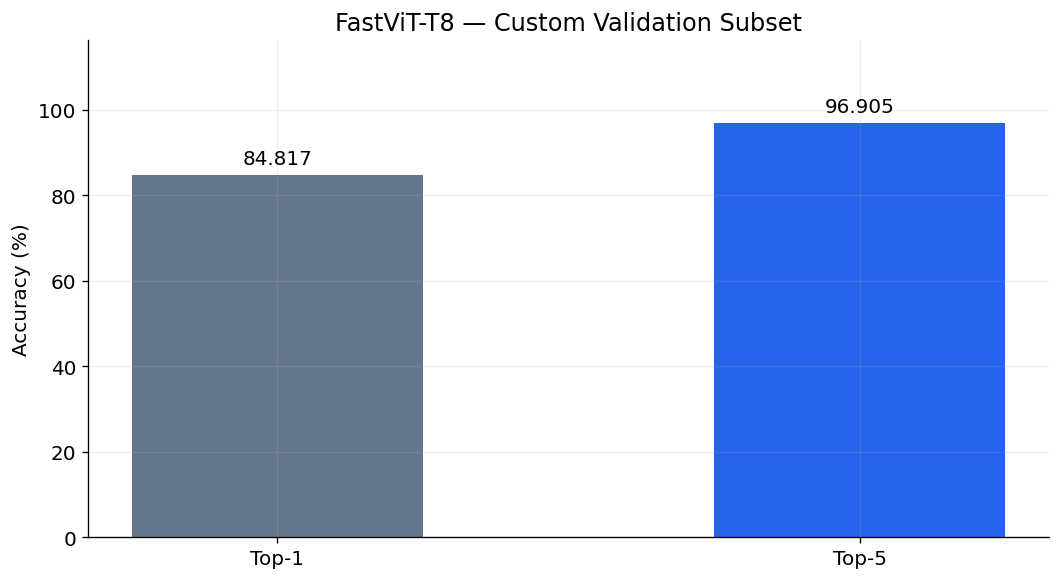

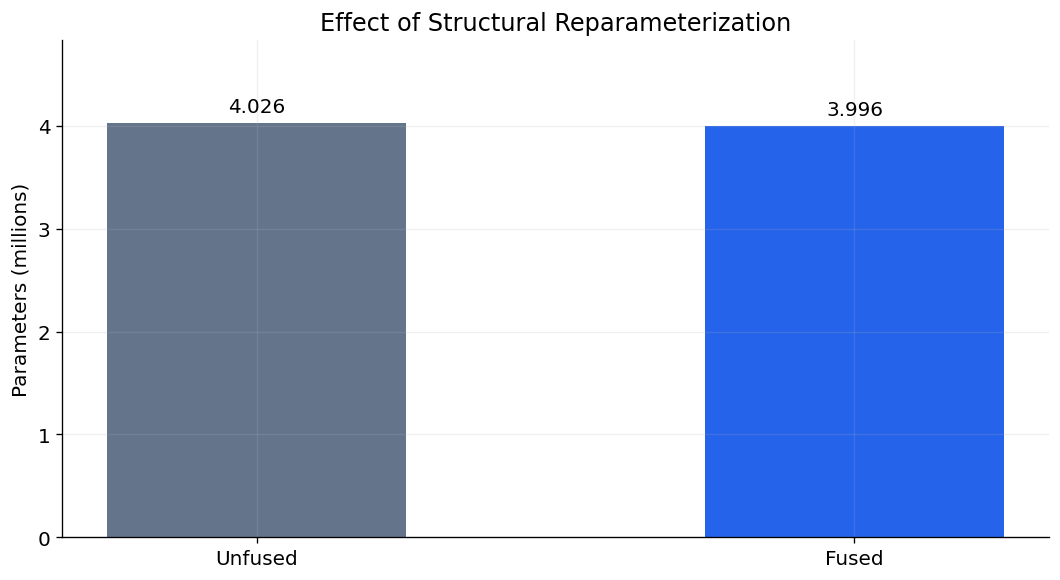

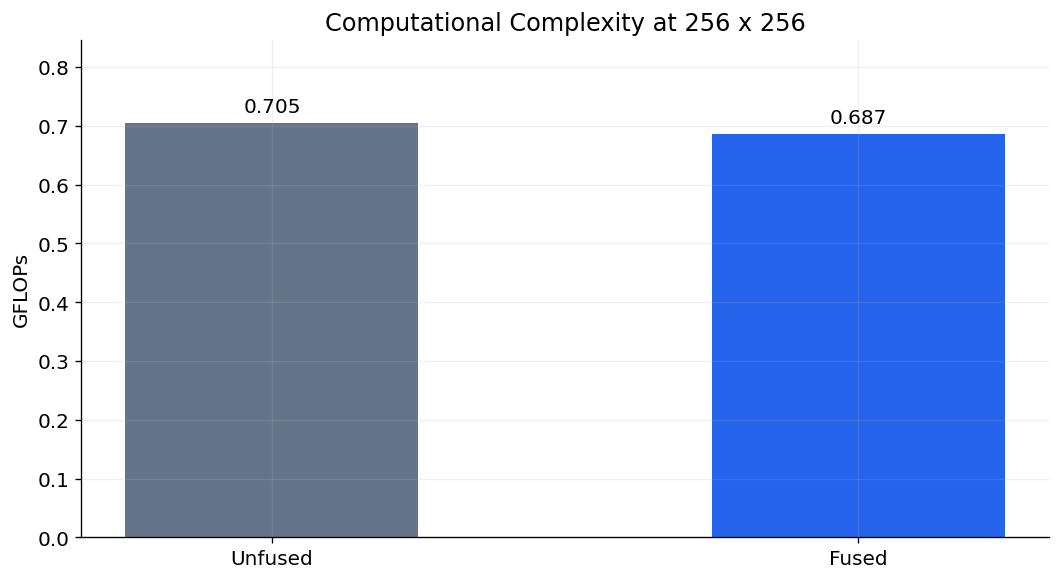

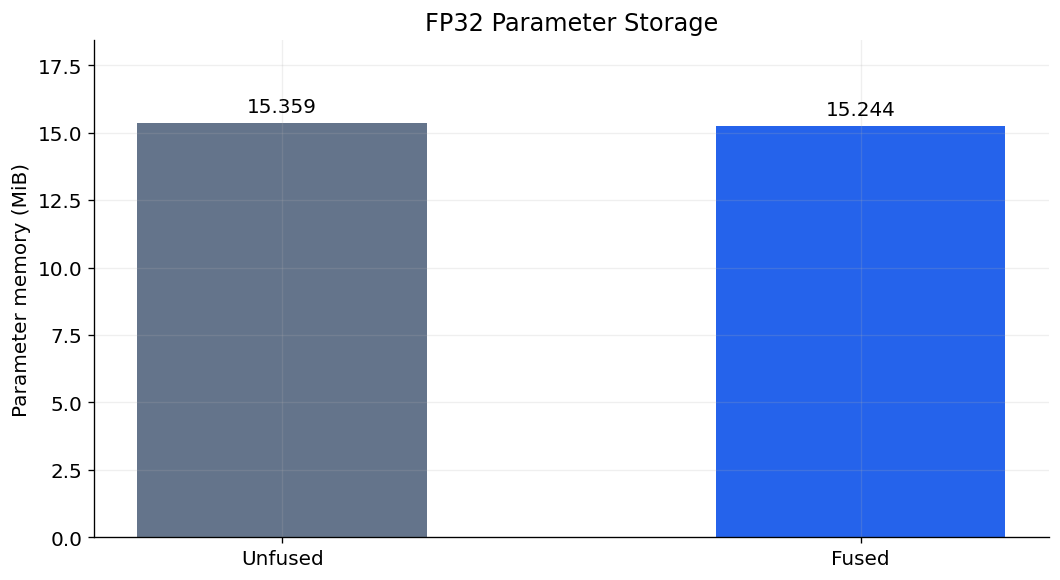

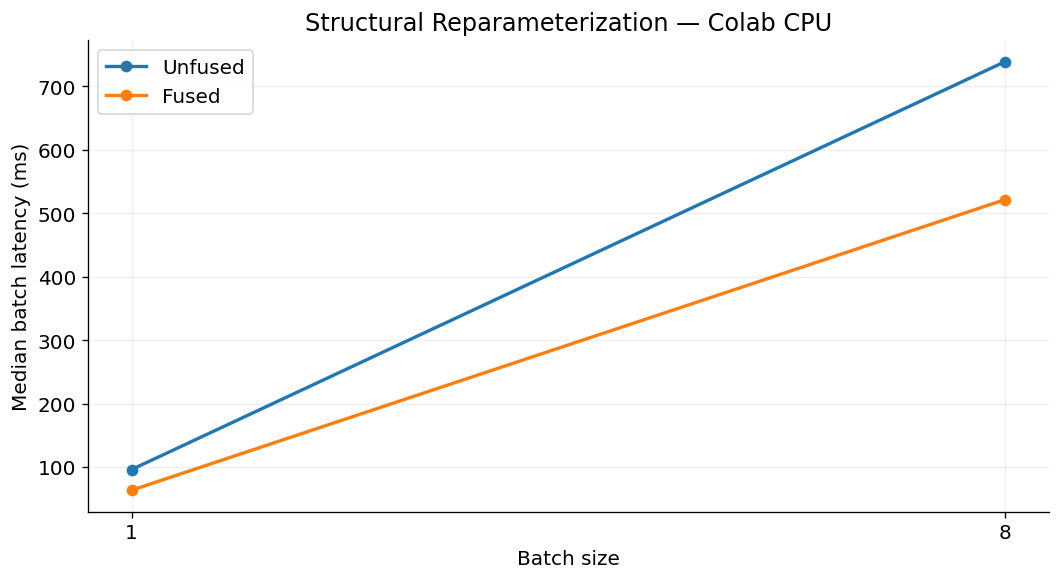

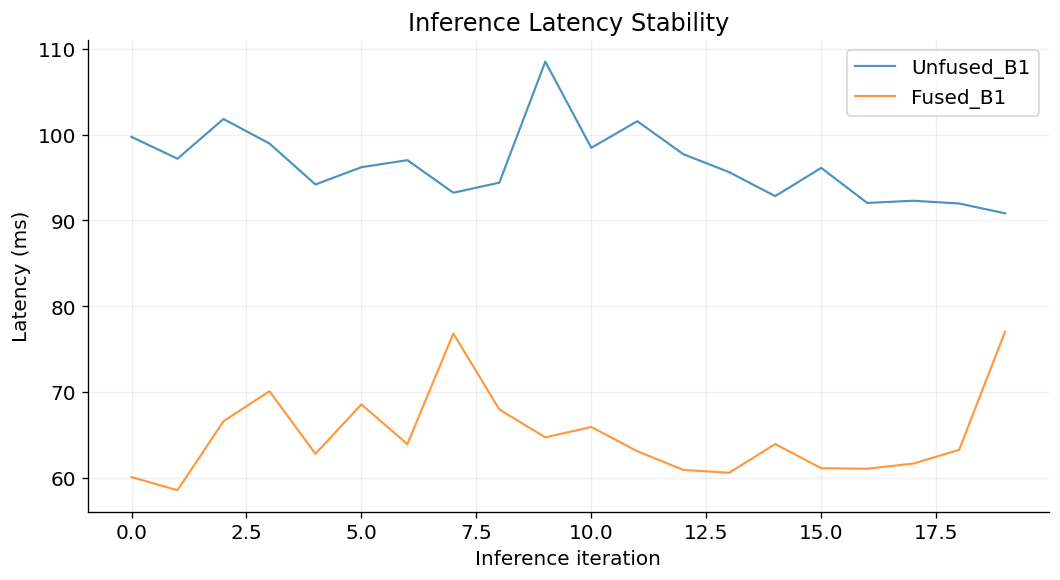

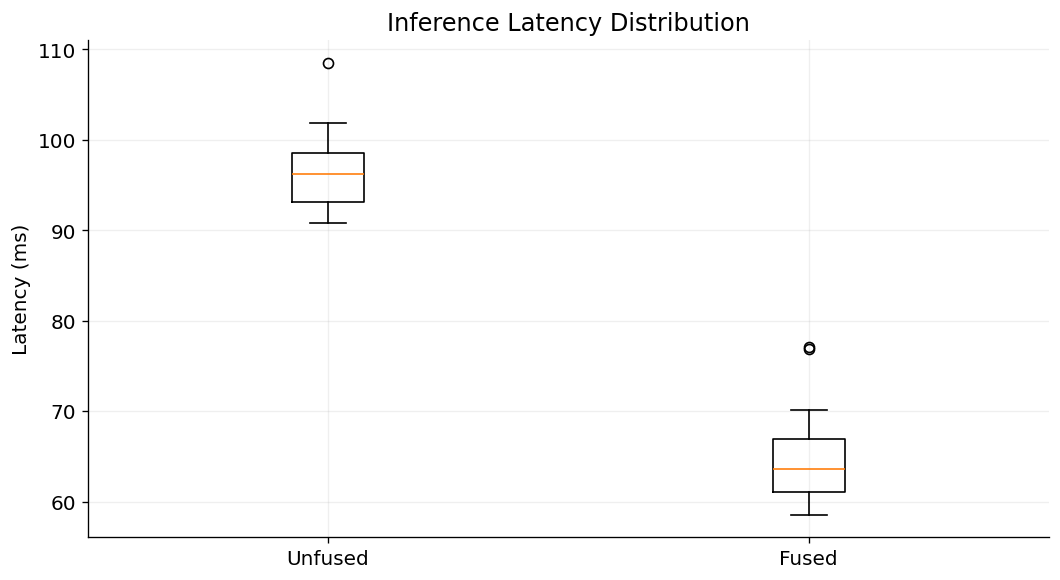

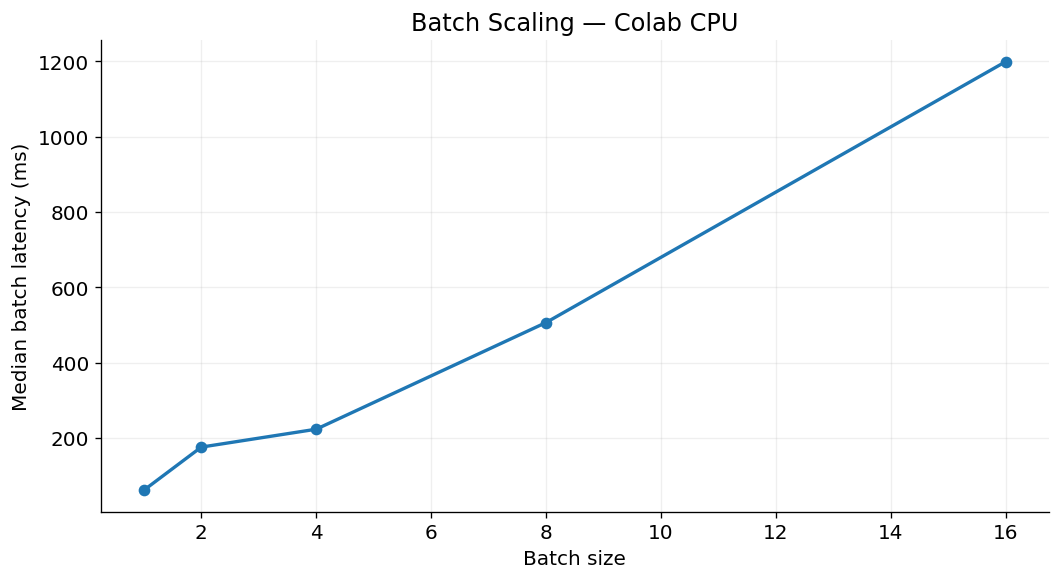

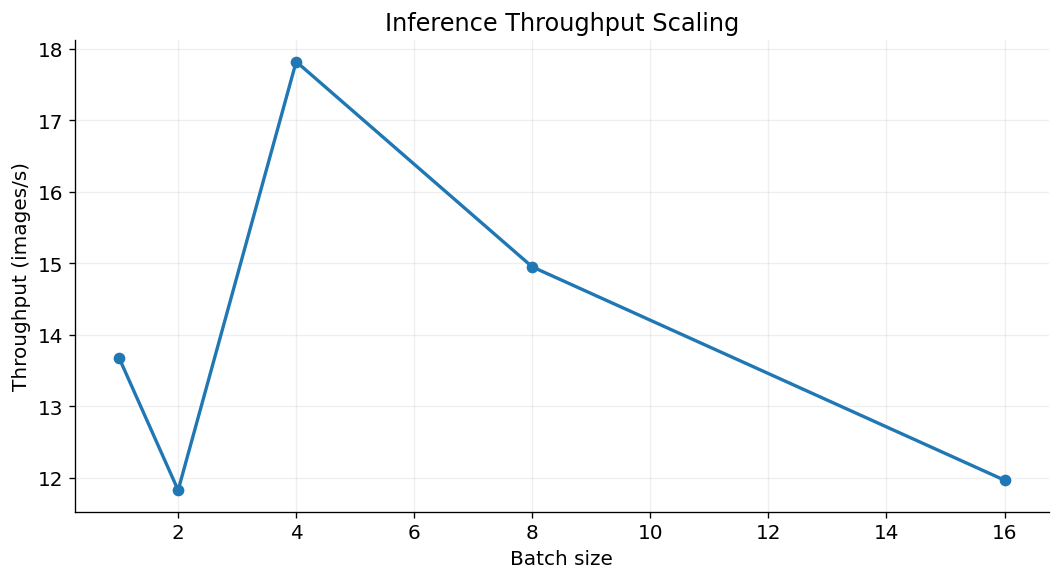

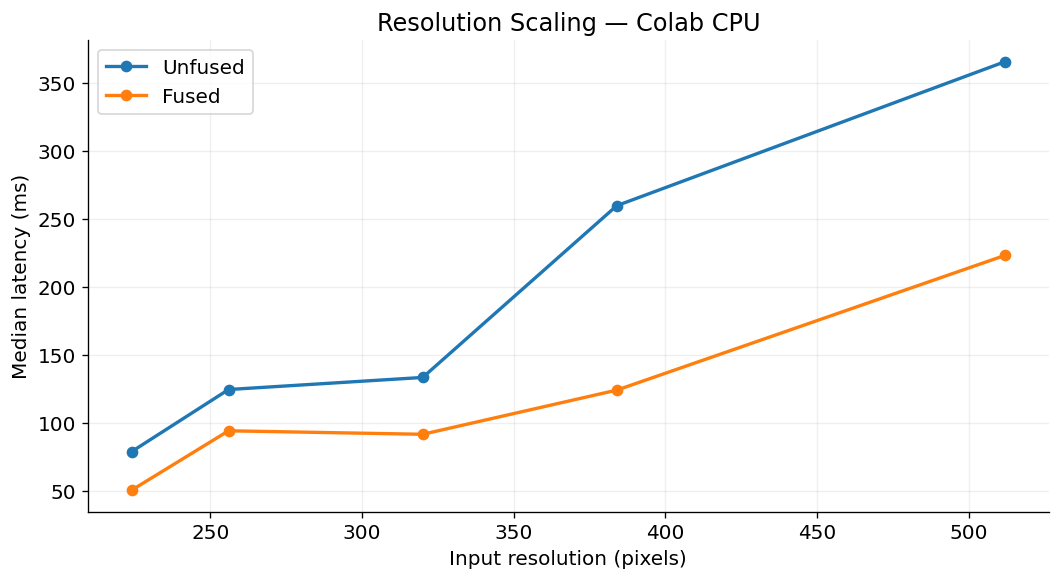

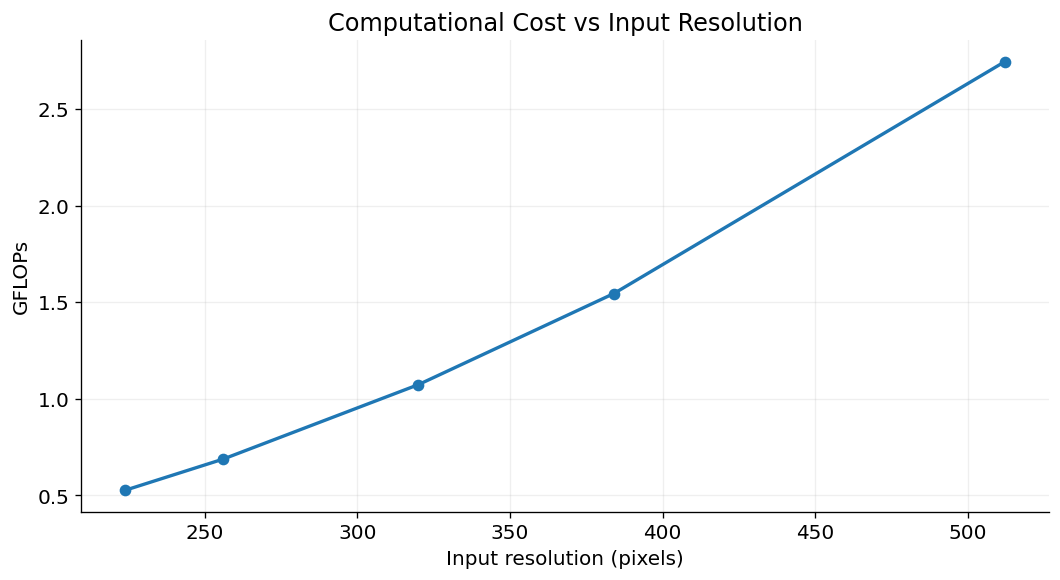

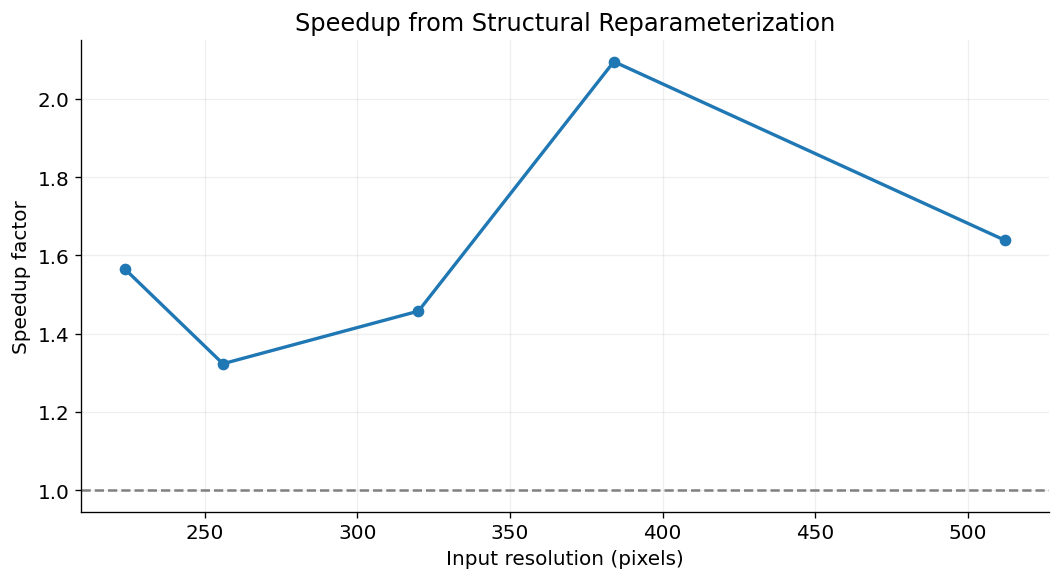


FINAL EXPERIMENTAL RESULTS
Hardware: Colab CPU
Backend: PyTorch FP32
Validation subset: 21293


,Metric,Paper,Our experiment
0,Input resolution,256.0,256.0000
1,Parameters (M),3.6,3.9960
2,GFLOPs,0.7,0.6869
3,Top-1 accuracy (%),75.6,84.8170
4,Top-5 accuracy (%),NaN,96.9050
5,Batch-8 latency (ms),1.7,521.6647
6,Mobile latency (ms),0.8,NaN
7,Batch-1 local latency (ms),NaN,63.5930
8,Batch-1 throughput (FPS),NaN,15.3997



All results saved to: /content/drive/MyDrive/FastViT_Evaluation


In [ ]:
import os
import sys
import time
import subprocess
import importlib.util
import urllib.request
from pathlib import Path
from io import StringIO

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from IPython.display import display

drive.mount("/content/drive")

REPO = Path("/content/ml-fastvit")
OUT = Path("/content/drive/MyDrive/FastViT_Evaluation")

OUT.mkdir(parents=True, exist_ok=True)

if not REPO.exists():
    subprocess.check_call([
        "git", "clone",
        "https://github.com/apple/ml-fastvit.git",
        str(REPO)
    ])

os.chdir(REPO)
sys.path.insert(0, str(REPO))

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "timm==0.9.16", "fvcore", "scipy"
])

import models

from timm.models import create_model, load_checkpoint
from models.modules.mobileone import reparameterize_model
from fvcore.nn import FlopCountAnalysis

torch.manual_seed(42)
np.random.seed(42)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

HARDWARE = (
    torch.cuda.get_device_name(0)
    if DEVICE.type == "cuda"
    else "Colab CPU"
)

WARMUP = 100 if DEVICE.type == "cuda" else 10
RUNS = 100 if DEVICE.type == "cuda" else 20

torch.backends.cudnn.benchmark = True

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 120,
    "font.size": 12,
    "axes.grid": True,
    "grid.alpha": 0.2,
    "axes.spines.top": False,
    "axes.spines.right": False
})

print("Hardware:", HARDWARE)
print("PyTorch:", torch.__version__)
print("Warm-up iterations:", WARMUP)
print("Measured iterations:", RUNS)


# 1. Load checkpoints

BASE_URL = (
    "https://docs-assets.developer.apple.com/"
    "ml-research/models/fastvit/image_classification_models/"
)

checkpoint_dir = REPO / "checkpoints"
checkpoint_dir.mkdir(exist_ok=True)

fused_path = checkpoint_dir / "fastvit_t8_reparam.pth.tar"
unfused_path = checkpoint_dir / "fastvit_t8.pth.tar"

for path in [fused_path, unfused_path]:
    if not path.exists() or path.stat().st_size < 1_000_000:
        urllib.request.urlretrieve(
            BASE_URL + path.name, path
        )

def load_model(path, inference_mode):
    net = create_model(
        "fastvit_t8",
        pretrained=False,
        inference_mode=inference_mode
    )

    load_checkpoint(net, str(path), use_ema=False)
    return net.eval()

unfused = load_model(unfused_path, False)
fused = load_model(fused_path, True)

converted = reparameterize_model(unfused).eval()

print("\nModels loaded successfully")


# 2. Reparameterization equivalence

x = torch.randn(1, 3, 256, 256)

with torch.inference_mode():
    y_unfused = unfused(x)
    y_converted = converted(x)
    y_official = fused(x)

difference = (y_unfused - y_converted).abs()

equivalence = {
    "Mean absolute error": difference.mean().item(),
    "Maximum absolute error": difference.max().item(),
    "RMSE": difference.square().mean().sqrt().item(),
    "Same top-1 prediction": (
        y_unfused.argmax(1) == y_converted.argmax(1)
    ).item(),
    "Converted vs official fused MAE": (
        y_converted - y_official
    ).abs().mean().item()
}

print("\nReparameterization equivalence")

for key, value in equivalence.items():
    print(f"{key}: {value}")

pd.DataFrame([equivalence]).to_csv(
    OUT / "equivalence.csv", index=False
)

del converted


# 3. Parameters and computational complexity

def complexity(net, resolution=256):
    x = torch.randn(1, 3, resolution, resolution)

    analysis = FlopCountAnalysis(net, x)
    analysis.unsupported_ops_warnings(False)
    analysis.uncalled_modules_warnings(False)
    analysis.tracer_warnings("none")

    flops = analysis.total()

    if resolution == 256:
        print("Unsupported operations:",
              analysis.unsupported_ops())

    params = sum(p.numel() for p in net.parameters())

    size = sum(
        p.numel() * p.element_size()
        for p in net.parameters()
    )

    return {
        "Parameters": params,
        "Parameters_M": params / 1e6,
        "GFLOPs": flops / 1e9,
        "Parameter_memory_MiB": size / 1024**2
    }

complexity_df = pd.DataFrame([
    {"Model": "Unfused", **complexity(unfused)},
    {"Model": "Fused", **complexity(fused)}
])

print("\nModel complexity")
display(complexity_df.round(4))

complexity_df.to_csv(
    OUT / "model_complexity.csv", index=False
)


# 4. Inference latency benchmark

unfused = unfused.to(DEVICE)
fused = fused.to(DEVICE)

def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

@torch.inference_mode()
def benchmark(net, batch=1, resolution=256):

    x = torch.randn(
        batch, 3, resolution, resolution,
        device=DEVICE
    )

    for _ in range(WARMUP):
        net(x)

    synchronize()

    times = []

    for _ in range(RUNS):

        synchronize()
        start = time.perf_counter()

        net(x)

        synchronize()

        times.append(
            (time.perf_counter() - start) * 1000
        )

    times = np.asarray(times)

    result = {
        "Batch_size": batch,
        "Resolution": resolution,
        "Mean_ms": times.mean(),
        "Median_ms": np.median(times),
        "Std_ms": times.std(),
        "P95_ms": np.percentile(times, 95),
        "Min_ms": times.min(),
        "Max_ms": times.max(),
        "Per_image_ms": times.mean() / batch,
        "Throughput_FPS": batch * 1000 / times.mean()
    }

    return result, times


# 5. Fused vs unfused latency

comparison = []
raw_times = {}

for name, net in [
    ("Unfused", unfused),
    ("Fused", fused)
]:

    for batch in [1, 8]:

        result, times = benchmark(net, batch, 256)

        comparison.append({
            "Model": name,
            **result
        })

        raw_times[f"{name}_B{batch}"] = times

        print(
            f"{name}, batch {batch}: "
            f"{result['Median_ms']:.3f} ms"
        )

comparison_df = pd.DataFrame(comparison)

comparison_df.to_csv(
    OUT / "reparameterization_latency.csv",
    index=False
)

pd.DataFrame(raw_times).to_csv(
    OUT / "raw_inference_times.csv",
    index=False
)

display(comparison_df.round(4))


# 6. Latency and throughput vs batch size

batch_sizes = (
    [1, 2, 4, 8, 16, 32, 64]
    if DEVICE.type == "cuda"
    else [1, 2, 4, 8, 16]
)

batch_results = []

for batch in batch_sizes:

    result, _ = benchmark(fused, batch, 256)
    batch_results.append(result)

    print(
        f"Batch {batch}: "
        f"{result['Median_ms']:.3f} ms | "
        f"{result['Throughput_FPS']:.2f} FPS"
    )

batch_df = pd.DataFrame(batch_results)

batch_df.to_csv(
    OUT / "batch_scaling.csv", index=False
)


# 7. Latency vs spatial resolution

resolutions = (
    [224, 256, 320, 384, 512, 640, 768, 1024]
    if DEVICE.type == "cuda"
    else [224, 256, 320, 384, 512]
)

resolution_results = []

for resolution in resolutions:

    for name, net in [
        ("Unfused", unfused),
        ("Fused", fused)
    ]:

        result, _ = benchmark(net, 1, resolution)

        resolution_results.append({
            "Model": name,
            **result
        })

        print(
            f"{name}, {resolution}x{resolution}: "
            f"{result['Median_ms']:.3f} ms"
        )

resolution_df = pd.DataFrame(resolution_results)

resolution_df.to_csv(
    OUT / "resolution_scaling.csv", index=False
)


# 8. FLOPs vs spatial resolution

fused = fused.cpu()

flop_results = []

for resolution in resolutions:

    result = complexity(fused, resolution)

    flop_results.append({
        "Resolution": resolution,
        "GFLOPs": result["GFLOPs"]
    })

flop_df = pd.DataFrame(flop_results)

flop_df.to_csv(
    OUT / "resolution_flops.csv", index=False
)


# 9. Previous validation results

TOP1 = 84.817
TOP5 = 96.905
N_IMAGES = 21293

validation_df = pd.DataFrame([{
    "Model": "FastViT-T8",
    "Top1": TOP1,
    "Top5": TOP5,
    "Top1_error": 100 - TOP1,
    "Top5_error": 100 - TOP5,
    "Validation_images": N_IMAGES,
    "Last_logged_batch_time_s": 25.959,
    "Last_logged_throughput": 2.47
}])

validation_df.to_csv(
    OUT / "validation_summary.csv", index=False
)


# 10. Generate and save plots

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / f"{name}.png",
                dpi=300, bbox_inches="tight")
    plt.savefig(OUT / f"{name}.pdf",
                bbox_inches="tight")
    plt.show()
    plt.close()

def bar_plot(labels, values, ylabel, title, name):

    plt.figure()

    bars = plt.bar(
        labels, values,
        color=["#64748B", "#2563EB"][:len(values)],
        width=0.5
    )

    plt.bar_label(bars, fmt="%.3f", padding=4)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.ylim(0, max(values) * 1.2)

    save_plot(name)


# Plot 1: Classification accuracy

bar_plot(
    ["Top-1", "Top-5"],
    [TOP1, TOP5],
    "Accuracy (%)",
    "FastViT-T8 — Custom Validation Subset",
    "01_classification_accuracy"
)


# Plot 2: Parameter count

bar_plot(
    complexity_df["Model"],
    complexity_df["Parameters_M"],
    "Parameters (millions)",
    "Effect of Structural Reparameterization",
    "02_parameter_count"
)


# Plot 3: Computational complexity

bar_plot(
    complexity_df["Model"],
    complexity_df["GFLOPs"],
    "GFLOPs",
    "Computational Complexity at 256 x 256",
    "03_computational_complexity"
)


# Plot 4: Parameter memory

bar_plot(
    complexity_df["Model"],
    complexity_df["Parameter_memory_MiB"],
    "Parameter memory (MiB)",
    "FP32 Parameter Storage",
    "04_parameter_memory"
)


# Plot 5: Fused vs unfused latency

plt.figure()

for name in ["Unfused", "Fused"]:

    df = comparison_df[
        comparison_df["Model"] == name
    ]

    plt.plot(
        df["Batch_size"],
        df["Median_ms"],
        "o-",
        linewidth=2,
        label=name
    )

plt.xticks([1, 8])
plt.xlabel("Batch size")
plt.ylabel("Median batch latency (ms)")
plt.title(f"Structural Reparameterization — {HARDWARE}")
plt.legend()

save_plot("05_reparameterization_latency")


# Plot 6: Inference latency per iteration

plt.figure()

for name in ["Unfused_B1", "Fused_B1"]:

    plt.plot(
        raw_times[name],
        alpha=0.8,
        linewidth=1.3,
        label=name
    )

plt.xlabel("Inference iteration")
plt.ylabel("Latency (ms)")
plt.title("Inference Latency Stability")
plt.legend()

save_plot("06_latency_iterations")


# Plot 7: Latency distribution

plt.figure()

plt.boxplot(
    [raw_times["Unfused_B1"],
     raw_times["Fused_B1"]]
)

plt.xticks([1, 2], ["Unfused", "Fused"])
plt.ylabel("Latency (ms)")
plt.title("Inference Latency Distribution")

save_plot("07_latency_distribution")


# Plot 8: Batch size vs latency

plt.figure()

plt.plot(
    batch_df["Batch_size"],
    batch_df["Median_ms"],
    "o-", linewidth=2
)

plt.xlabel("Batch size")
plt.ylabel("Median batch latency (ms)")
plt.title(f"Batch Scaling — {HARDWARE}")

save_plot("08_batch_latency")


# Plot 9: Batch size vs throughput

plt.figure()

plt.plot(
    batch_df["Batch_size"],
    batch_df["Throughput_FPS"],
    "o-", linewidth=2
)

plt.xlabel("Batch size")
plt.ylabel("Throughput (images/s)")
plt.title("Inference Throughput Scaling")

save_plot("09_batch_throughput")


# Plot 10: Resolution vs latency

plt.figure()

for name in ["Unfused", "Fused"]:

    df = resolution_df[
        resolution_df["Model"] == name
    ]

    plt.plot(
        df["Resolution"],
        df["Median_ms"],
        "o-",
        linewidth=2,
        label=name
    )

plt.xlabel("Input resolution (pixels)")
plt.ylabel("Median latency (ms)")
plt.title(f"Resolution Scaling — {HARDWARE}")
plt.legend()

save_plot("10_resolution_latency")


# Plot 11: Resolution vs FLOPs

plt.figure()

plt.plot(
    flop_df["Resolution"],
    flop_df["GFLOPs"],
    "o-", linewidth=2
)

plt.xlabel("Input resolution (pixels)")
plt.ylabel("GFLOPs")
plt.title("Computational Cost vs Input Resolution")

save_plot("11_resolution_flops")


# Plot 12: Reparameterization speedup

speedup_df = resolution_df.pivot(
    index="Resolution",
    columns="Model",
    values="Median_ms"
).reset_index()

speedup_df["Speedup"] = (
    speedup_df["Unfused"] /
    speedup_df["Fused"]
)

plt.figure()

plt.plot(
    speedup_df["Resolution"],
    speedup_df["Speedup"],
    "o-", linewidth=2
)

plt.axhline(1, linestyle="--", color="gray")
plt.xlabel("Input resolution (pixels)")
plt.ylabel("Speedup factor")
plt.title("Speedup from Structural Reparameterization")

save_plot("12_reparameterization_speedup")

speedup_df.to_csv(
    OUT / "reparameterization_speedup.csv",
    index=False
)


# 11. Final comparison with the paper

fused_stats = complexity_df[
    complexity_df["Model"] == "Fused"
].iloc[0]

b8 = comparison_df[
    (comparison_df["Model"] == "Fused") &
    (comparison_df["Batch_size"] == 8)
].iloc[0]

b1 = comparison_df[
    (comparison_df["Model"] == "Fused") &
    (comparison_df["Batch_size"] == 1)
].iloc[0]

summary = pd.DataFrame({
    "Metric": [
        "Input resolution",
        "Parameters (M)",
        "GFLOPs",
        "Top-1 accuracy (%)",
        "Top-5 accuracy (%)",
        "Batch-8 latency (ms)",
        "Mobile latency (ms)",
        "Batch-1 local latency (ms)",
        "Batch-1 throughput (FPS)"
    ],
    "Paper": [
        256, 3.6, 0.7, 75.6, np.nan,
        1.7, 0.8, np.nan, np.nan
    ],
    "Our experiment": [
        256,
        fused_stats["Parameters_M"],
        fused_stats["GFLOPs"],
        TOP1,
        TOP5,
        b8["Median_ms"],
        np.nan,
        b1["Median_ms"],
        b1["Throughput_FPS"]
    ]
})

print("\nFINAL EXPERIMENTAL RESULTS")
print("Hardware:", HARDWARE)
print("Backend: PyTorch FP32")
print("Validation subset:", N_IMAGES)

display(summary.round(4))

summary.to_csv(
    OUT / "final_comparison.csv", index=False
)

print("\nAll results saved to:", OUT)

In [ ]:
from models.fastvit import fastvit_t8

for ratio in [1.0, 2.0]:

    net = fastvit_t8(
        pretrained=False,
        inference_mode=True,
        cls_ratio=ratio
    )

    total = sum(p.numel() for p in net.parameters())
    head = sum(p.numel() for p in net.head.parameters())
    expansion = sum(p.numel() for p in net.conv_exp.parameters())

    print(f"\nClassifier ratio: {ratio}")
    print(f"Classifier: {net.head}")
    print(f"FC parameters: {head:,}")
    print(f"Expansion parameters: {expansion:,}")
    print(f"Total parameters: {total:,}")
    print(f"Parameters (M): {total / 1e6:.4f}")


Classifier ratio: 1.0
Classifier: Linear(in_features=384, out_features=1000, bias=True)
FC parameters: 385,000
Expansion parameters: 22,680
Total parameters: 3,552,496
Parameters (M): 3.5525

Classifier ratio: 2.0
Classifier: Linear(in_features=768, out_features=1000, bias=True)
FC parameters: 769,000
Expansion parameters: 82,224
Total parameters: 3,996,040
Parameters (M): 3.9960
